# 06. Workplace Safety & Discrimination Trends (2014–2024)

This notebook loads the harmonized master dataset and generates clean, publication-ready trend visualizations using Seaborn and Matplotlib. It tracks the evolution of workplace safety, harassment, and discrimination indicators in Finland over the decade.

In [1]:
# ==========================================
# 1. IMPORTS & LOAD PROCESSED DATA
# ==========================================
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import pandas as pd

# Load the harmonized master dataset from the root directory
input_path = "harmonized_safety_indicators.csv"
master_safety_df = pd.read_csv(input_path)

print(f"Loaded dataset successfully. Shape: {master_safety_df.shape}")

Loaded dataset successfully. Shape: (19475, 4)


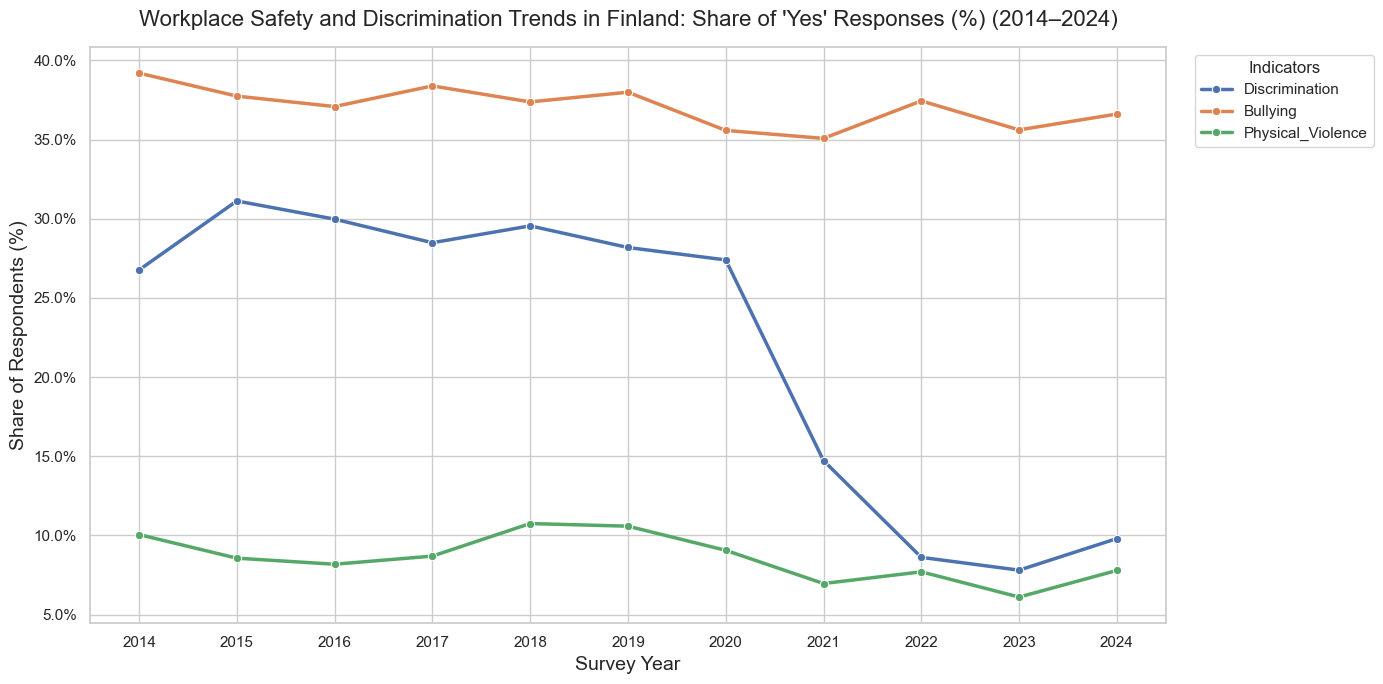

In [2]:
# ==========================================
# 2. PERCENTAGE TREND VISUALIZATION (0–100%)
# ==========================================

indicators = [
    "Discrimination",
    "Bullying",
    "Physical_Violence",
]

# Calculate percentage and multiply by 100
pct_df = (
    master_safety_df.groupby("Year")[indicators]
    .mean()
    .reset_index()
)
pct_df[indicators] = pct_df[indicators] * 100

melted_pct_df = pd.melt(
    pct_df,
    id_vars=["Year"],
    value_vars=indicators,
    var_name="Indicator",
    value_name="Percentage",
)

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=melted_pct_df,
    x="Year",
    y="Percentage",
    hue="Indicator",
    marker="o",
    linewidth=2.5,
)

plt.title(
    "Workplace Safety and Discrimination Trends in Finland: Share of 'Yes' Responses (%) (2014–2024)",
    fontsize=16,
    pad=15,
)
plt.xlabel("Survey Year", fontsize=14)
plt.ylabel("Share of Respondents (%)", fontsize=14)

# Optional: add '%' sign to Y-axis ticks
plt.gca().yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))

plt.xticks(sorted(master_safety_df["Year"].unique()))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Indicators")
plt.tight_layout()
plt.show()